# Epoch motifs with Gaussian expression levels

Mouse 720762, deep prelimbic LFP (PL5), the report's 10 bands. Algorithm in `src/epoch_motifs.py`:

1. Detect motifs (relaxed Mishler, or every candidate with its p-value) separately in each epoch: spontaneous awake,
   awake + electrical, awake + visual, early isoflurane, isoflurane + electrical, isoflurane + visual, late isoflurane.
2. Union of directions across epochs: axes with |cosine| ≥ `cos_merge` become one motif.
3. For every epoch and motif, a 1-D GMM with 3 components started at −`init_scale`, 0, +`init_scale` on the
   seconds projected onto the axis. Projections use one global z-scoring so positions compare across epochs.
4. Per motif, merge epoch Gaussians closer than `merge_d` (separation d′ = gap in means / pooled SD), ignoring
   Gaussians with weight < `min_weight`. The number of groups is k.
5. A k-component GMM per motif over the whole recording, started at the group means. Every second gets a
   responsibility for every Gaussian of every motif.
6. A zero motif (baseline): RMS of the bands below 0.5 z (`rms`), or near zero on every motif (`nearzero`).

Sections: the evidence behind the premises; one run walked through; the hyperparameter sweep; whether k is set by the
data or by the threshold; held-out checks.

## Evaluation of the approach before running it

**Supported by earlier work**
- *Motifs appear only in some epochs:* finer time bins gave 4.5× more candidates (18 vs 4 on PL5); strict motifs appear only while awake.
- *Expression and pole positions differ between states:* the permutation test found pole balance differs between awake and isoflurane chunks (p = 0.008); the 10-D mixture split the recording into epochs.
- *Zero/baseline as its own label:* quiet seconds are 1.2–1.5× more common than in a matched Gaussian under isoflurane.
- *Asymmetric pole positions:* 2-component weights 0.24 / 0.76 on isoflurane M1 put the low pole about 3× farther from zero.

**Not supported, or risks**
- *Directions consistent across states:* motifs found separately in awake and isoflurane differ (bootstrap |r| 0.37 across vs 0.97 within). The union handles either case, but expect few merges between awake and isoflurane.
- *Three Gaussians per epoch:* within spontaneous epochs the projections are one hump, so 3 components slice a continuum; their positions are set by the data's spread, not by clusters.
- *Comparing positions across epochs needs one z-scoring,* and then awake vs isoflurane level differences dominate the positions.
- *"Distinct Gaussians" needs a threshold,* and if there are no natural groups, k is whatever the threshold makes it (tested in section 4).
- *A zero vector has no direction,* so the zero motif has to be defined separately (here: RMS of the bands, or near zero on every motif).

In [1]:
import sys
from dataclasses import replace
from itertools import product
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "..")
from src import epoch_motifs as em
from src import gmm_motifs as gx
from src import session_data as sd
from src.state_motifs import band_labels
%matplotlib inline
import warnings; warnings.filterwarnings("ignore")

REPO = Path.cwd().resolve().parents[2]
NWB = REPO / "data" / "raw" / "720762-20240221-v001.nwb"
OUT = REPO / "data" / "out" / "2026-11-09_epoch_motifs"
OUT.mkdir(parents=True, exist_ok=True)
names = band_labels()
EP = list(em.EPOCHS)
ECOL = dict(zip(EP, ["#1f77b4", "#ff7f0e", "#2ca02c", "#9467bd", "#d62728", "#8c564b", "#e377c2"]))

def save(fig, name):
    fig.savefig(OUT / f"{name}.png", dpi=130, bbox_inches="tight")

io, nwb = sd.open_nwb(NWB)
beh = nwb.processing["behavior"]
rs = beh["BehavioralTimeSeries"]["running_speed"]
run_speed = rs.data[:]
run_t = rs.timestamps[:] if rs.timestamps is not None else rs.starting_time + np.arange(run_speed.size) / rs.rate
pw = beh["PupilTracking"]["pupil_width"]
pupil, pupil_t = pw.data[:], pw.timestamps[:]
io.close()

data = em.load(NWB)
dets = {s: em.detect_epochs(data, s) for s in ("relaxed", "none")}
pd.DataFrame({"seconds": pd.Series(data.epoch).value_counts().reindex(EP),
              "relaxed motifs": pd.Series([e for e, _, _ in dets["relaxed"]]).value_counts().reindex(EP).fillna(0).astype(int),
              "all candidates (p as score)": pd.Series([e for e, _, _ in dets["none"]]).value_counts().reindex(EP).fillna(0).astype(int)}).T

,awake,awake_electrical,awake_visual,iso_early,iso_electrical,iso_visual,iso_late
seconds,947,1651,530,1181,1651,523,207
relaxed motifs,0,2,1,2,1,3,2
all candidates (p as score),10,10,10,9,8,7,4


Note: the relaxed version finds nothing in spontaneous awake time on this channel (947 s), so with `relaxed` the
spontaneous awake epoch only contributes through motifs found elsewhere. `none` keeps every candidate.

## 1. Do the same directions recur across epochs?

Premise 1 is that motif directions are mostly shared across epochs and only expression differs. For every pair of epochs:
the best |cosine| between each axis in one epoch and any axis in the other (all candidates, `none`), averaged. Then
the same for random unit vectors as a reference (what you get by chance in 10 dimensions).

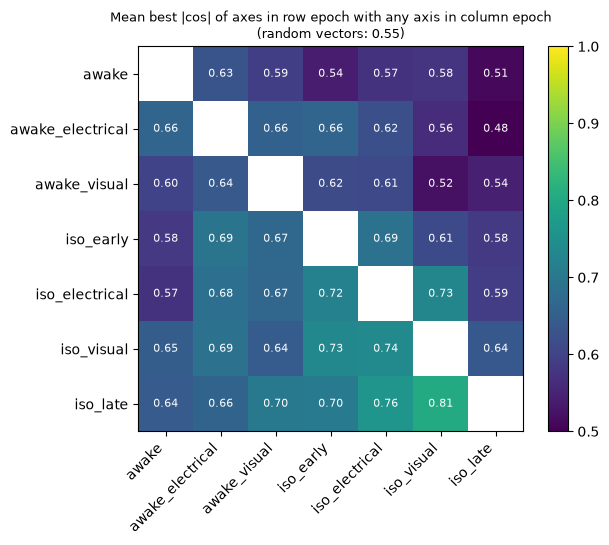

In [2]:
ax_by_ep = {e: np.array([u for ee, u, _ in dets["none"] if ee == e]) for e in EP}
M = pd.DataFrame(index=EP, columns=EP, dtype=float)
for a, b in product(EP, EP):
    if len(ax_by_ep[a]) and len(ax_by_ep[b]) and a != b:
        M.loc[a, b] = np.abs(ax_by_ep[a] @ ax_by_ep[b].T).max(axis=1).mean()
rng = np.random.default_rng(0)
rand = []
for a, b in product(EP, EP):
    if a != b and len(ax_by_ep[a]) and len(ax_by_ep[b]):
        R1 = rng.standard_normal((len(ax_by_ep[a]), 10)); R2 = rng.standard_normal((len(ax_by_ep[b]), 10))
        R1 /= np.linalg.norm(R1, axis=1, keepdims=True); R2 /= np.linalg.norm(R2, axis=1, keepdims=True)
        rand.append(np.abs(R1 @ R2.T).max(axis=1).mean())
fig, ax = plt.subplots(figsize=(6.5, 5))
im = ax.imshow(M.values.astype(float), cmap="viridis", vmin=0.5, vmax=1)
for i in range(len(EP)):
    for j in range(len(EP)):
        if np.isfinite(M.values[i, j]):
            ax.text(j, i, f"{M.values[i, j]:.2f}", ha="center", va="center", fontsize=8, color="w")
ax.set_xticks(range(len(EP)), EP, rotation=45, ha="right"); ax.set_yticks(range(len(EP)), EP)
ax.set_title(f"Mean best |cos| of axes in row epoch with any axis in column epoch\n(random vectors: {np.mean(rand):.2f})", fontsize=9)
fig.colorbar(im, ax=ax); save(fig, "1_axis_recurrence"); plt.show()

## 2. One run, walked through

Setting: relaxed detection, `cos_merge` 0.9, `init_scale` 1, `merge_d` 3, `min_weight` 0.05, baseline `rms`.
(`merge_d` 3 is used here because it gives about 3 Gaussians per motif, the size you had in mind; section 3 shows
the others.)

7 motifs


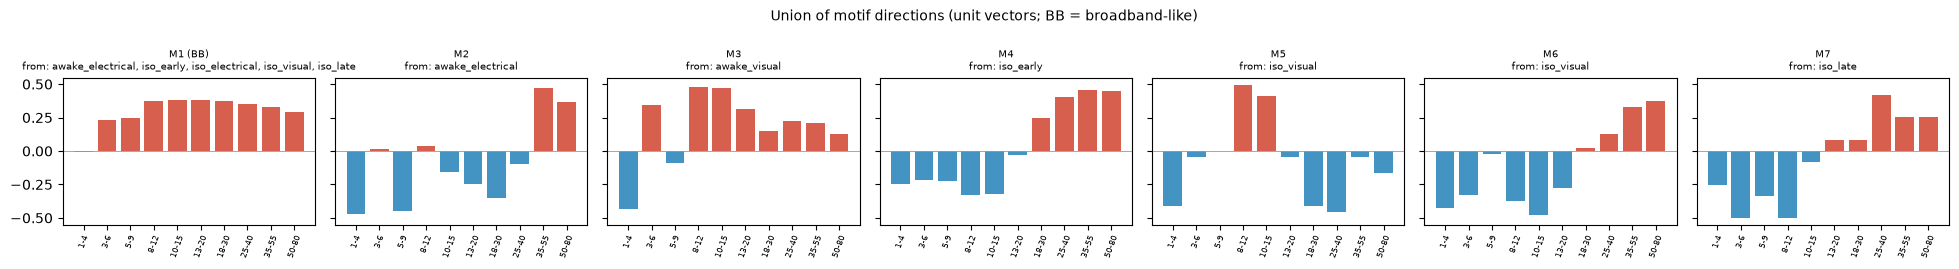

,motif,comp,label,mean,sd,weight,broadband,found_in
0,0,0,M1:-4.6,-4.57,0.53,0.12,True,"awake_electrical,iso_early,iso_electrical,iso_..."
1,0,1,M1:-2.9,-2.91,1.10,0.10,True,"awake_electrical,iso_early,iso_electrical,iso_..."
2,0,2,M1:+1.0,0.97,0.50,0.47,True,"awake_electrical,iso_early,iso_electrical,iso_..."
3,0,3,M1:+1.3,1.26,2.16,0.31,True,"awake_electrical,iso_early,iso_electrical,iso_..."
4,1,0,M2:-1.3,-1.34,1.21,0.29,False,awake_electrical
5,1,1,M2:+0.3,0.27,0.37,0.48,False,awake_electrical
6,1,2,M2:+1.2,1.17,0.49,0.22,False,awake_electrical
7,2,0,M3:-2.7,-2.65,0.39,0.13,False,awake_visual
8,2,1,M3:-1.1,-1.13,1.06,0.10,False,awake_visual
9,2,2,M3:+0.3,0.30,0.48,0.42,False,awake_visual


In [3]:
P0 = em.Params(merge_d=3.0)
res = em.run(data, dets["relaxed"], P0)
print(len(res.motifs), "motifs")
fig, axes = plt.subplots(1, len(res.motifs), figsize=(2.8 * len(res.motifs), 2.7), sharey=True, squeeze=False)
for i, (ax, m) in enumerate(zip(axes[0], res.motifs)):
    u = m.template
    ax.bar(range(10), u, color=np.where(u >= 0, "#d6604d", "#4393c3")); ax.axhline(0, color="0.6", lw=0.6)
    ax.set_xticks(range(10), names, rotation=70, fontsize=6)
    ax.set_title(f"M{i + 1}{' (BB)' if m.broadband else ''}\nfrom: {', '.join(m.epochs)}", fontsize=7)
fig.suptitle("Union of motif directions (unit vectors; BB = broadband-like)", fontsize=10)
fig.tight_layout(); save(fig, "2_union_templates"); plt.show()
res.comps.round(2)

For each motif: each row is an epoch (its seconds projected onto the axis, global z units) with its three
Gaussians. Colour = the group each Gaussian was merged into; grey dashed = ignored (weight below `min_weight`). Bottom
row: the whole recording with the final k Gaussians.

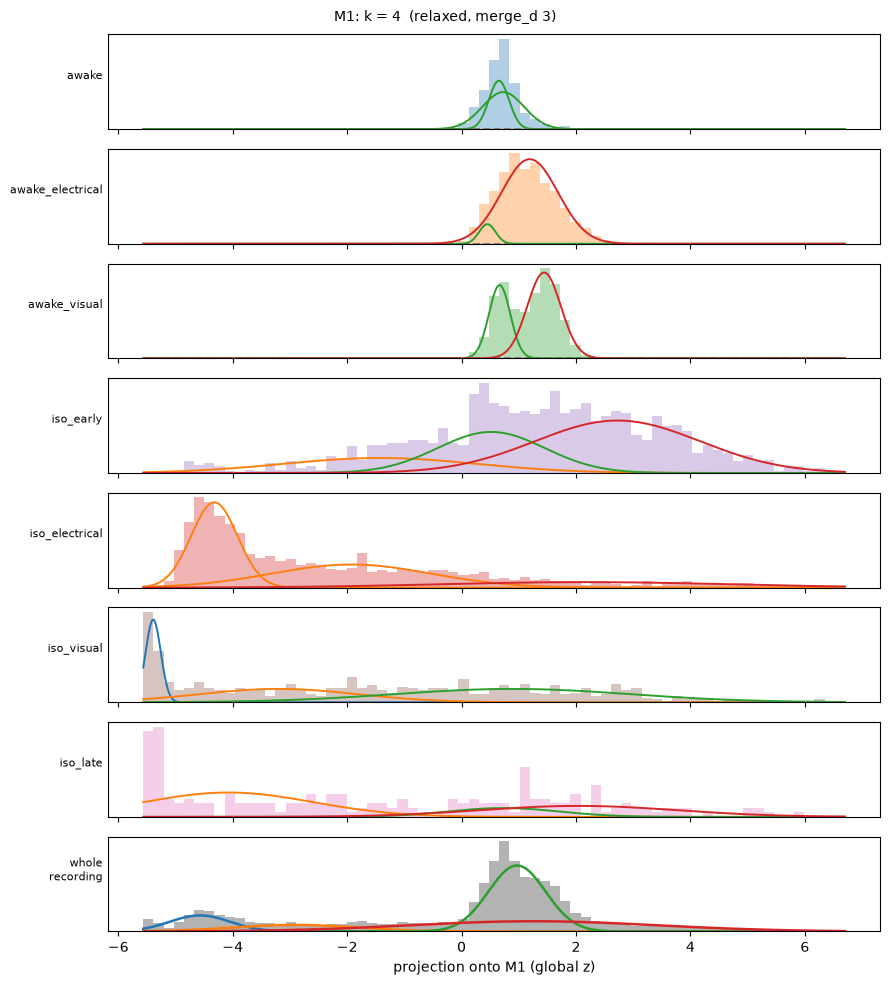

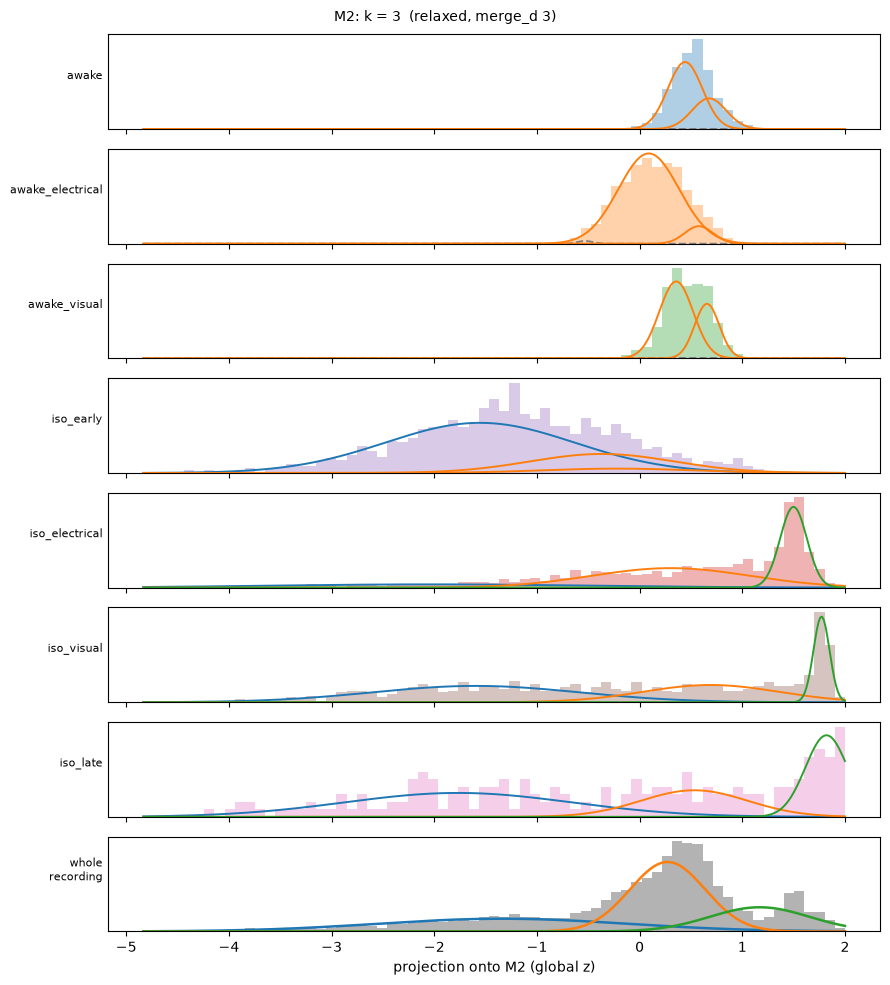

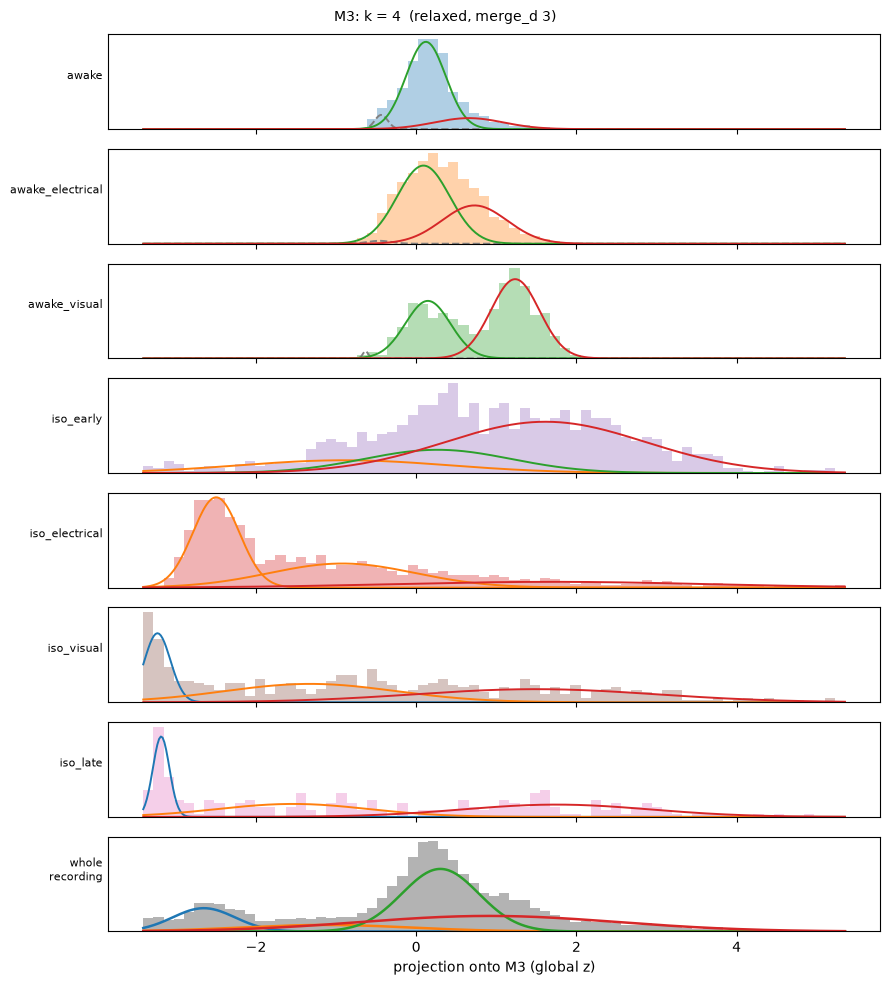

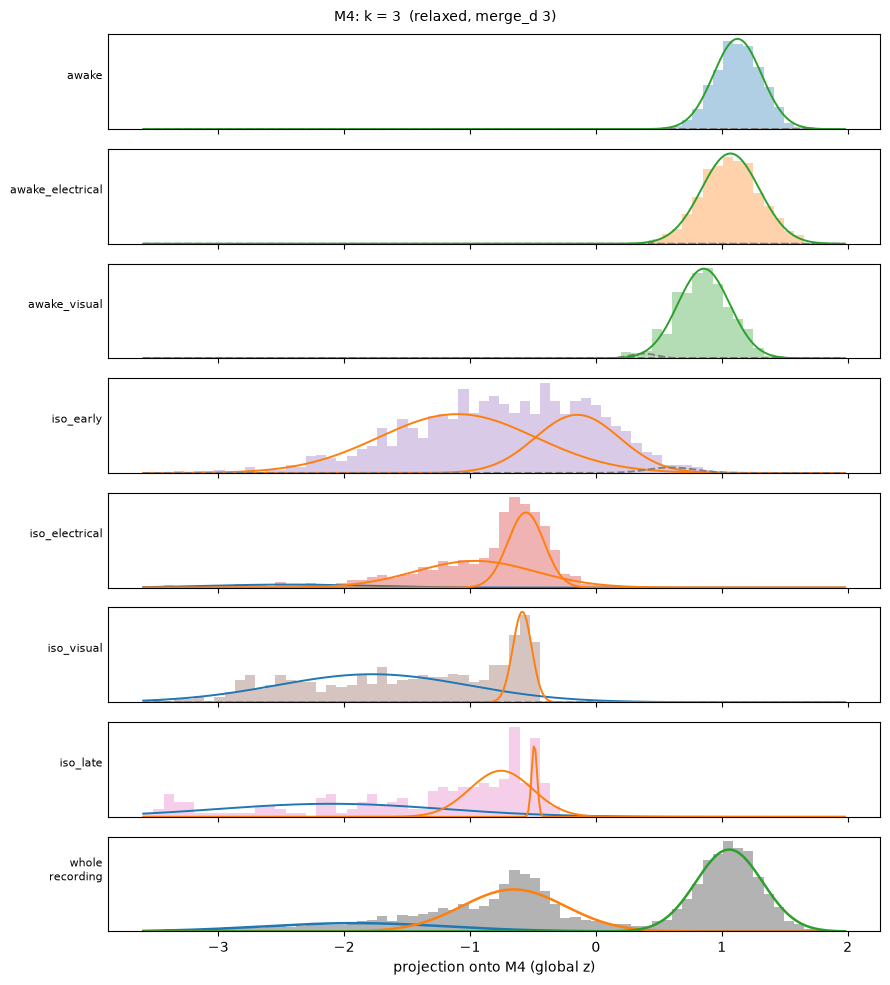

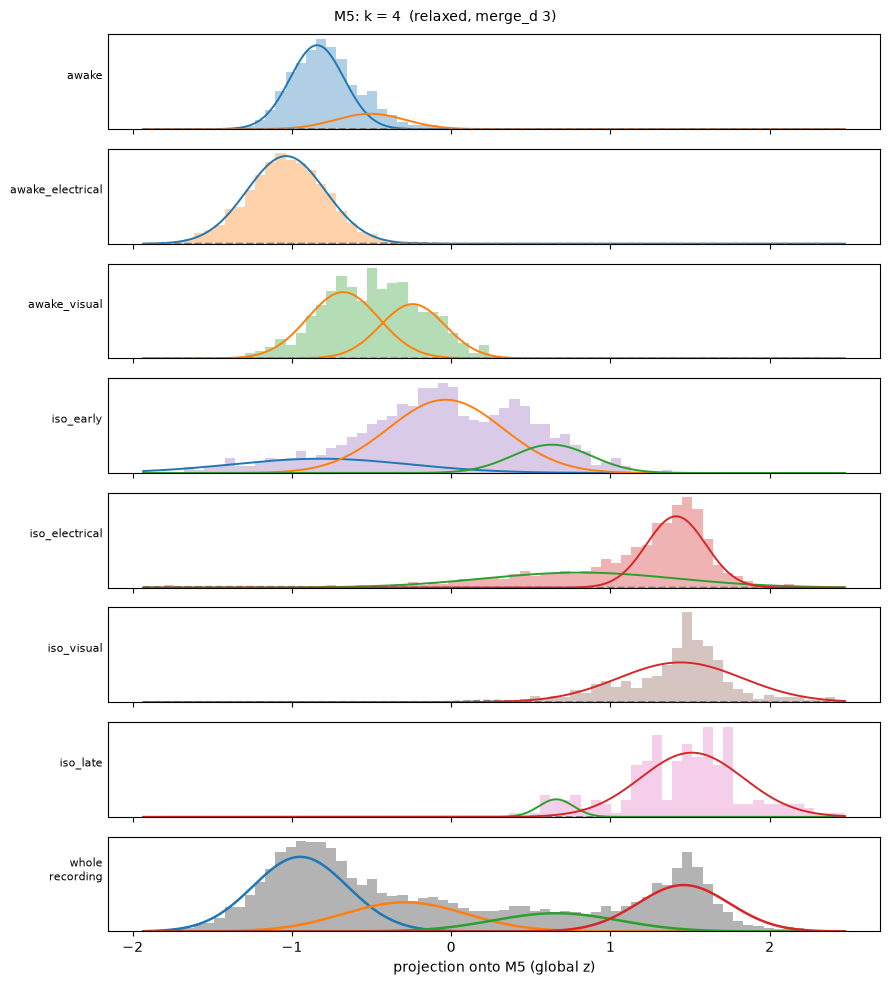

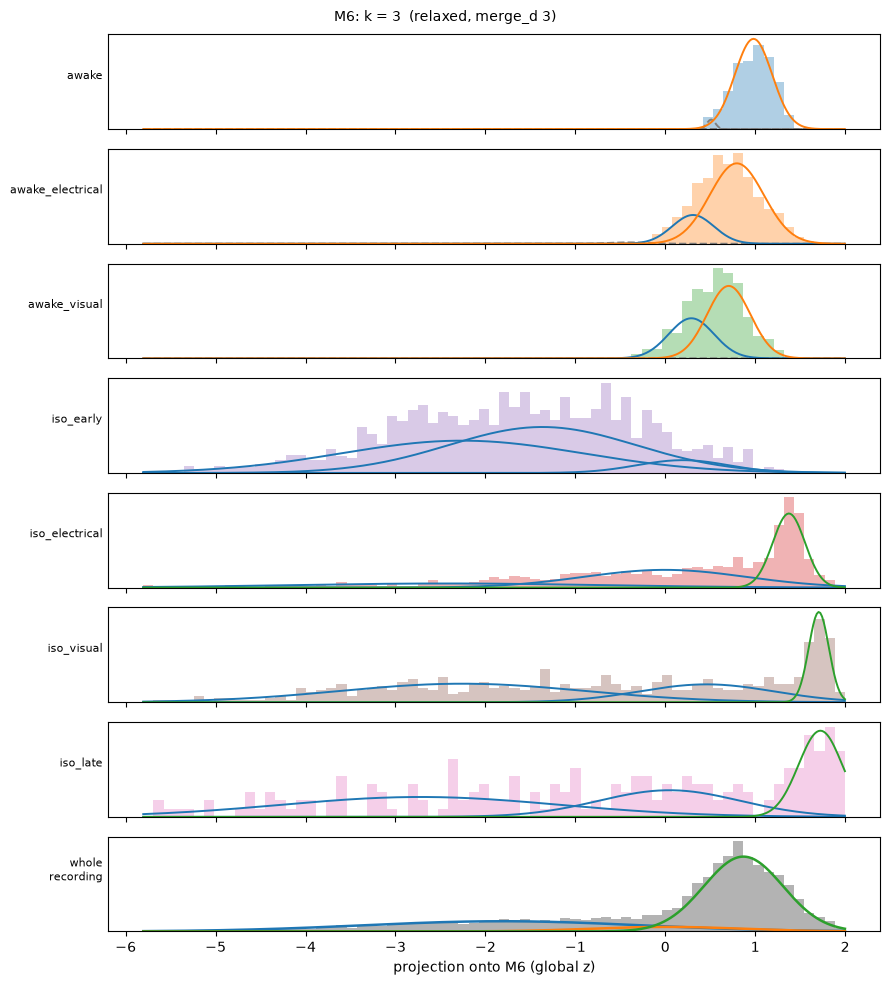

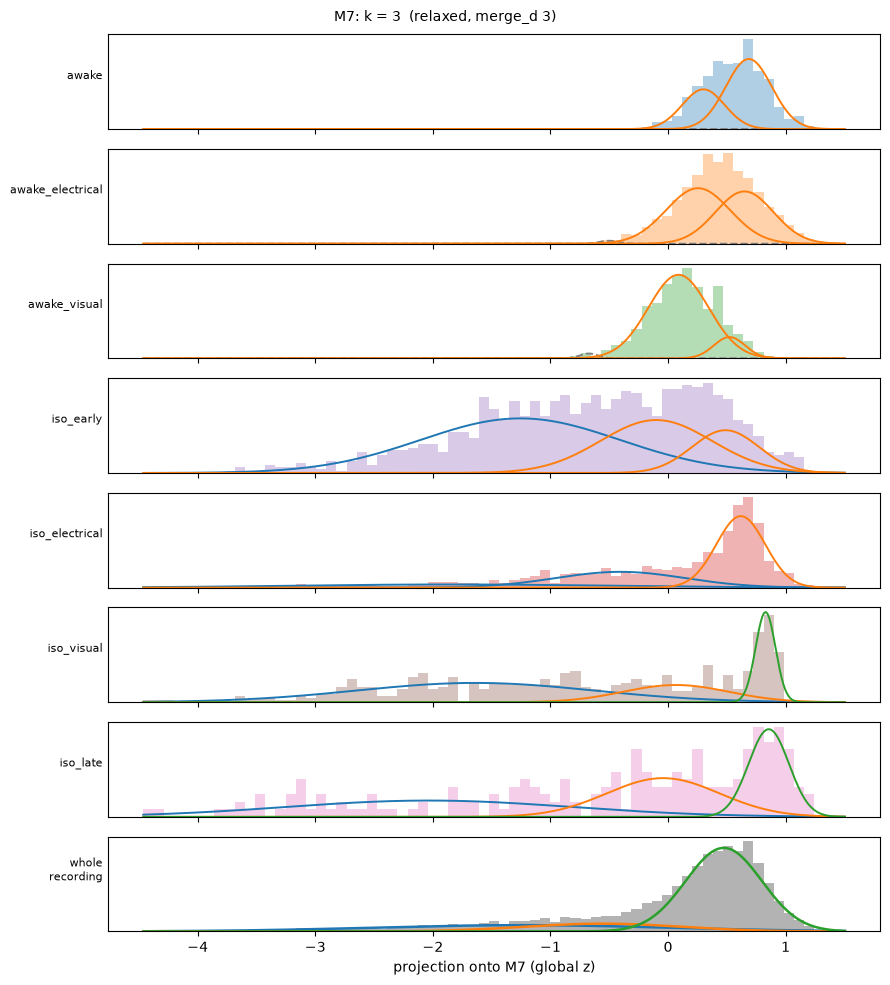

In [4]:
def norm_pdf(x, mu, sd):
    return np.exp(-(x - mu) ** 2 / (2 * sd ** 2)) / (sd * np.sqrt(2 * np.pi))

def walkthrough(res, mi, tag):
    score = res.scores[:, mi]
    xs = np.linspace(np.percentile(score, 0.2), np.percentile(score, 99.8), 400)
    eps = [e for e in EP if (data.epoch == e).any()]
    fig, axes = plt.subplots(len(eps) + 1, 1, figsize=(9, 1.25 * (len(eps) + 1)), sharex=True)
    cmap = plt.get_cmap("tab10")
    g = res.epoch_gauss[res.epoch_gauss.motif == mi]
    for ax, e in zip(axes, eps):
        x = score[data.epoch == e]
        ax.hist(x, bins=np.linspace(xs[0], xs[-1], 70), density=True, color=ECOL[e], alpha=0.35)
        for _, r in g[g.epoch == e].iterrows():
            grp = int(r["group"])
            ax.plot(xs, r["weight"] * norm_pdf(xs, r["mean"], max(r["sd"], 1e-3)),
                    color=cmap(grp) if grp >= 0 else "0.5", ls="-" if grp >= 0 else "--", lw=1.4)
        ax.set_ylabel(e, rotation=0, ha="right", fontsize=8); ax.set_yticks([])
    ax = axes[-1]
    ax.hist(score, bins=np.linspace(xs[0], xs[-1], 70), density=True, color="0.7")
    c = res.comps[res.comps.motif == mi]
    for j, (_, r) in enumerate(c.iterrows()):
        ax.plot(xs, r["weight"] * norm_pdf(xs, r["mean"], r["sd"]), color=cmap(j), lw=1.8)
    ax.set_ylabel("whole\nrecording", rotation=0, ha="right", fontsize=8); ax.set_yticks([])
    ax.set_xlabel(f"projection onto M{mi + 1} (global z)")
    fig.suptitle(f"M{mi + 1}: k = {len(c)}  ({tag})", fontsize=10)
    fig.tight_layout(); save(fig, f"2_walkthrough_M{mi + 1}"); plt.show()

for mi in range(len(res.motifs)):
    walkthrough(res, mi, "relaxed, merge_d 3")

Mean responsibility of each final Gaussian in each epoch (and the baseline motif's share).

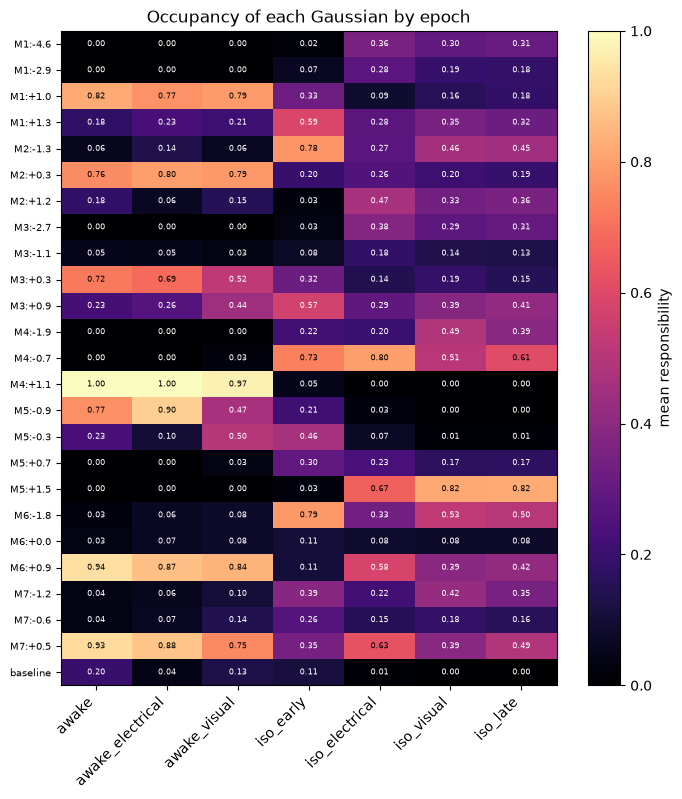

NMI between each motif's hard Gaussian labels and the epoch labels: [0.3  0.29 0.25 0.49 0.45 0.24 0.14]


In [5]:
occ = em.occupancy(res, data)
fig, ax = plt.subplots(figsize=(8, 0.28 * len(occ) + 1.5))
im = ax.imshow(occ.values, aspect="auto", cmap="magma", vmin=0, vmax=1)
ax.set_yticks(range(len(occ)), occ.index, fontsize=7); ax.set_xticks(range(occ.shape[1]), occ.columns, rotation=45, ha="right")
for i in range(occ.shape[0]):
    for j in range(occ.shape[1]):
        ax.text(j, i, f"{occ.values[i, j]:.2f}", ha="center", va="center", fontsize=6, color="w" if occ.values[i, j] < 0.6 else "k")
fig.colorbar(im, ax=ax, label="mean responsibility"); ax.set_title("Occupancy of each Gaussian by epoch")
save(fig, "2_occupancy"); plt.show()
print("NMI between each motif's hard Gaussian labels and the epoch labels:", em.epoch_nmi(res, data).round(2))

Responsibilities over the recording with isoflurane, stimulus blocks (orange electrical, blue visual), running and pupil; last row = baseline motif.

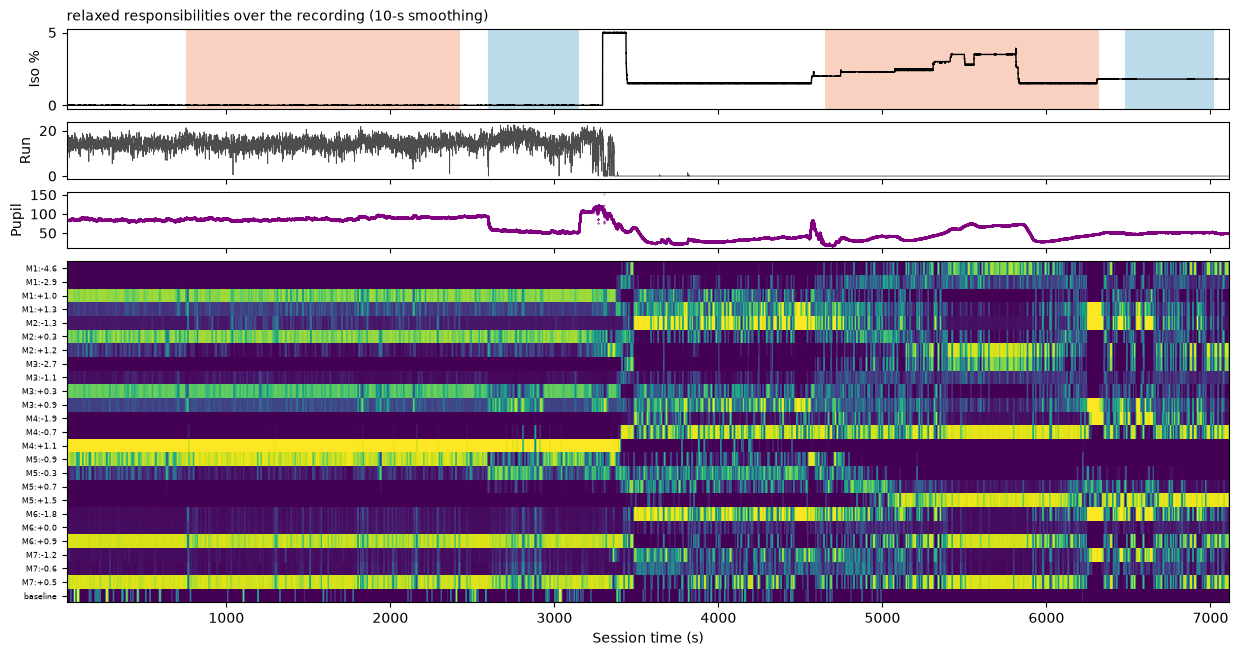

baseline share: rms 0.072, nearzero 0.001; correlation between the two: 0.26


In [6]:
def smooth(v, n):
    return np.convolve(v, np.ones(n) / n, mode="same")

def timeline(res, name):
    info = data.info
    labels = list(res.comps["label"]) + ["baseline"]
    Rb = np.column_stack([res.R, res.baseline])
    fig = plt.figure(figsize=(15, 3.2 + 0.17 * len(labels)))
    gs = fig.add_gridspec(4, 1, height_ratios=[1, 0.7, 0.7, max(2.5, 0.17 * len(labels))], hspace=0.1)
    ax0 = fig.add_subplot(gs[0])
    ax0.plot(info.iso_t, info.iso_level, color="k", lw=1); ax0.set_ylabel("Iso %")
    for _, a, b in info.stim_blocks:
        ax0.axvspan(a, b, color="#f4a582", alpha=0.5, lw=0)
    for _, a, b in info.visual_blocks:
        ax0.axvspan(a, b, color="#92c5de", alpha=0.6, lw=0)
    ax1 = fig.add_subplot(gs[1], sharex=ax0); ax1.plot(run_t, smooth(run_speed, 100), color="0.3", lw=0.6); ax1.set_ylabel("Run")
    ax2 = fig.add_subplot(gs[2], sharex=ax0); ax2.plot(pupil_t, pupil, ".", ms=0.4, color="purple"); ax2.set_ylabel("Pupil")
    ax3 = fig.add_subplot(gs[3], sharex=ax0)
    ax3.imshow(np.array([smooth(c, 10) for c in Rb.T]), aspect="auto", cmap="viridis", vmin=0, vmax=1,
               interpolation="none", extent=[data.t[0], data.t[-1], len(labels) - 0.5, -0.5])
    ax3.set_yticks(range(len(labels)), labels, fontsize=6); ax3.set_xlabel("Session time (s)")
    for a in (ax0, ax1, ax2):
        plt.setp(a.get_xticklabels(), visible=False)
    ax0.set_xlim(data.t[0], data.t[-1])
    ax0.set_title(name, loc="left", fontsize=10)
    save(fig, f"2_timeline_{name.split()[0]}"); plt.show()

timeline(res, "relaxed responsibilities over the recording (10-s smoothing)")
base_nz = em.run(data, dets["relaxed"], replace(P0, baseline="nearzero")).baseline
print(f"baseline share: rms {res.baseline.mean():.3f}, nearzero {base_nz.mean():.3f}; "
      f"correlation between the two: {np.corrcoef(res.baseline, base_nz)[0, 1]:.2f}")

## 3. Hyperparameter sweep

Grid: detection (`relaxed`, `none`) × `cos_merge` (0.8, 0.9, 0.95) × `merge_d` (0.5, 1, 1.5, 2, 3, 4, 6) ×
`init_scale` (0.5, 1, 2) × `min_weight` (0.02, 0.05, 0.1). Metrics per run: number of motifs (and not broadband),
total Gaussians, mean and max k, motifs with k ≥ 2, NMI between Gaussian labels and epochs (how much the Gaussians are
just epoch labels), baseline share.

In [7]:
grid = [em.Params(significance=s, cos_merge=c, merge_d=d, init_scale=i, min_weight=w)
        for s, c, d, i, w in product(("relaxed", "none"), (0.8, 0.9, 0.95), (0.5, 1, 1.5, 2, 3, 4, 6), (0.5, 1, 2), (0.02, 0.05, 0.1))]
sw = em.sweep(data, dets, grid)
sw.to_csv(OUT / "sweep.csv", index=False)
print(len(sw), "runs")
sw.groupby(["significance", "cos_merge"])[["n_motifs", "n_not_broadband"]].first()

378 runs


n_motifs  n_not_broadband
significance cos_merge                           
none         0.80             43               40
             0.90             52               49
             0.95             53               50
relaxed      0.80              5                4
             0.90              7                6
             0.95              7                6

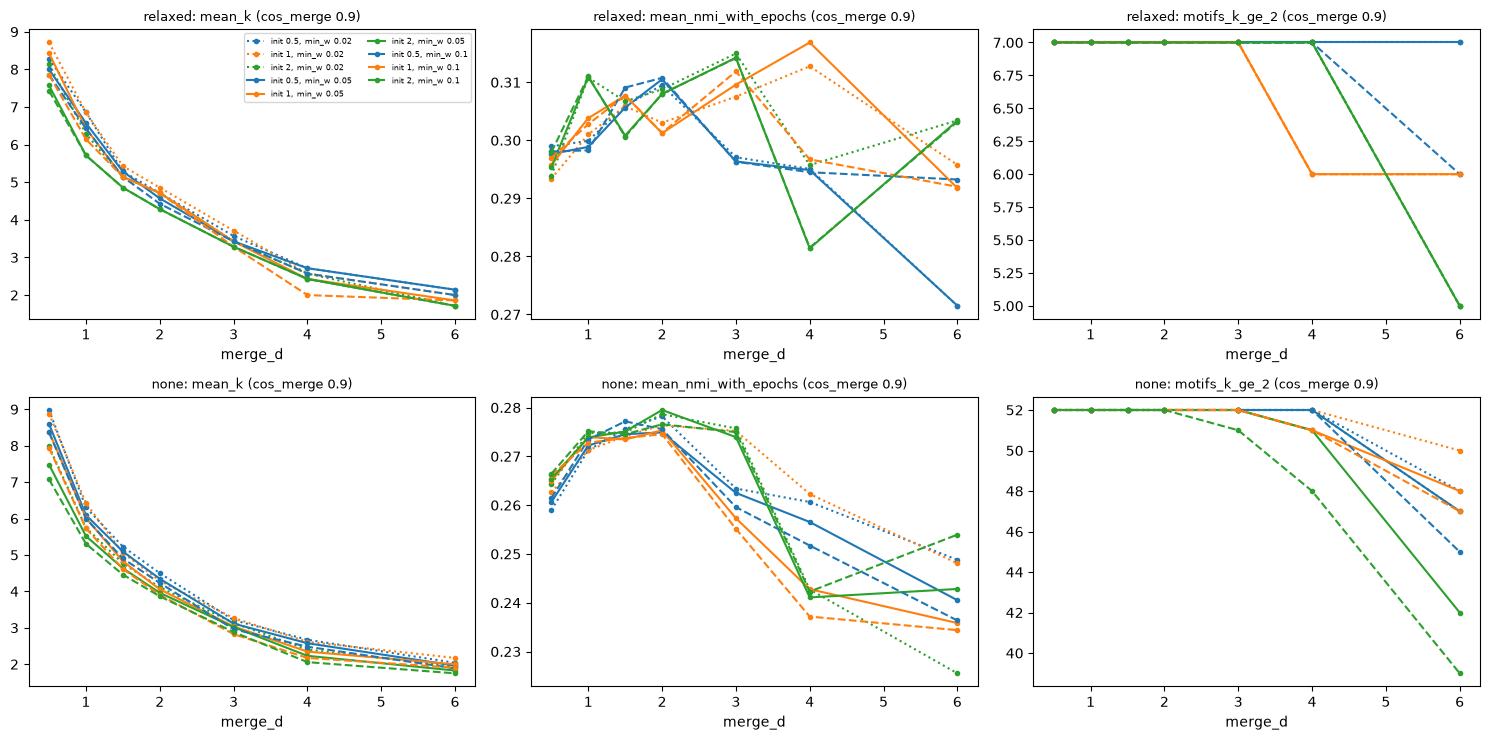

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
for row, sig in enumerate(("relaxed", "none")):
    s = sw[(sw.significance == sig) & (sw.cos_merge == 0.9)]
    for ax, metric in zip(axes[row], ("mean_k", "mean_nmi_with_epochs", "motifs_k_ge_2")):
        for w, ls in zip((0.02, 0.05, 0.1), (":", "-", "--")):
            for i, col in zip((0.5, 1, 2), ("C0", "C1", "C2")):
                q = s[(s.min_weight == w) & (s.init_scale == i)].sort_values("merge_d")
                ax.plot(q.merge_d, q[metric], ls=ls, color=col, marker="o", ms=3,
                        label=f"init {i}, min_w {w}" if row == 0 and metric == "mean_k" else None)
        ax.set_title(f"{sig}: {metric} (cos_merge 0.9)", fontsize=9); ax.set_xlabel("merge_d")
axes[0, 0].legend(fontsize=6, ncol=2)
fig.tight_layout(); save(fig, "3_sweep_merge_d"); plt.show()

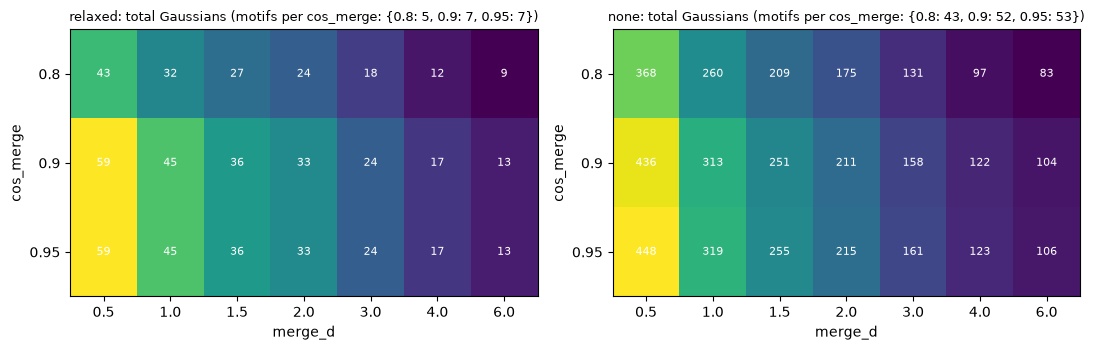

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, sig in zip(axes, ("relaxed", "none")):
    s = sw[(sw.significance == sig) & (sw.init_scale == 1) & (sw.min_weight == 0.05)]
    piv = s.pivot(index="cos_merge", columns="merge_d", values="total_components")
    im = ax.imshow(piv.values, cmap="viridis", aspect="auto")
    for i in range(piv.shape[0]):
        for j in range(piv.shape[1]):
            ax.text(j, i, int(piv.values[i, j]), ha="center", va="center", fontsize=8, color="w")
    ax.set_xticks(range(piv.shape[1]), piv.columns); ax.set_yticks(range(piv.shape[0]), piv.index)
    ax.set_xlabel("merge_d"); ax.set_ylabel("cos_merge")
    nm = s.groupby("cos_merge").n_motifs.first().to_dict()
    ax.set_title(f"{sig}: total Gaussians (motifs per cos_merge: {nm})", fontsize=9)
fig.tight_layout(); save(fig, "3_sweep_total_components"); plt.show()

Split-half stability (alternating 5-minute blocks): share of motifs whose k is the same in both halves, at the default `cos_merge`, `init_scale` and `min_weight`.

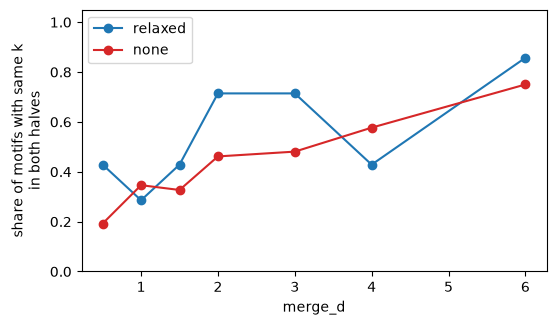

,significance,merge_d,n_motifs,mean_k,share_same_k_split_half,mean_nmi_with_epochs
0,relaxed,0.5,7,8.43,0.43,0.30
1,relaxed,1.0,7,6.43,0.29,0.30
2,relaxed,1.5,7,5.14,0.43,0.31
3,relaxed,2.0,7,4.71,0.71,0.30
4,relaxed,3.0,7,3.43,0.71,0.31
5,relaxed,4.0,7,2.43,0.43,0.32
6,relaxed,6.0,7,1.86,0.86,0.29
7,none,0.5,52,8.38,0.19,0.26
8,none,1.0,52,6.02,0.35,0.27
9,none,1.5,52,4.83,0.33,0.27


In [10]:
stab = em.sweep(data, dets, [em.Params(significance=s, merge_d=d) for s in ("relaxed", "none") for d in (0.5, 1, 1.5, 2, 3, 4, 6)],
               with_stability=True)
stab.to_csv(OUT / "stability.csv", index=False)
fig, ax = plt.subplots(figsize=(6, 3.4))
for sig, col in (("relaxed", "C0"), ("none", "C3")):
    q = stab[stab.significance == sig]
    ax.plot(q.merge_d, q.share_same_k_split_half, "o-", color=col, label=sig)
ax.set_xlabel("merge_d"); ax.set_ylabel("share of motifs with same k\nin both halves"); ax.legend(); ax.set_ylim(0, 1.05)
save(fig, "3_stability"); plt.show()
stab[["significance", "merge_d", "n_motifs", "mean_k", "share_same_k_split_half", "mean_nmi_with_epochs"]].round(2)

## 4. Is k set by the data or by the threshold?

If the epoch Gaussians formed real, separate groups, the number of groups would stay flat over a range of
`merge_d` (a plateau) before dropping. A smooth decline means the Gaussians are spread continuously and k is whatever
the threshold makes it. Per motif, k against `merge_d` on a fine grid (relaxed, defaults otherwise).

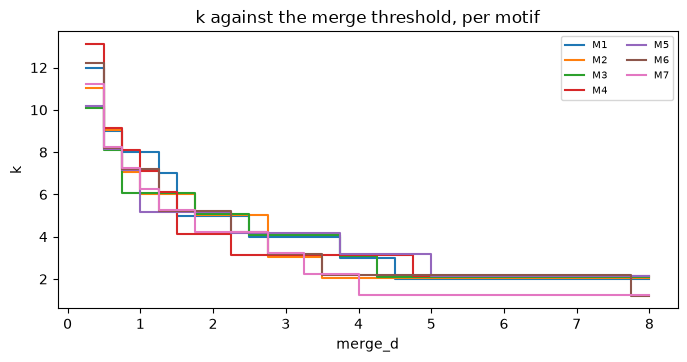

,k with the longest plateau (k > 1),plateau length (d' units)
M1,2,3.75
M2,2,4.75
M3,2,4.00
M4,2,3.50
M5,2,3.25
M6,2,4.25
M7,4,1.00


In [11]:
ds = np.round(np.arange(0.25, 8.01, 0.25), 2)
motifs0 = em.union_axes(dets["relaxed"], 0.9)
eg0 = em.epoch_gaussians(data, motifs0, em.Params())
K = np.array([[len(em.merge_gaussians(eg0[eg0.motif == mi], d, 0.05)[1]) for d in ds] for mi in range(len(motifs0))])
fig, ax = plt.subplots(figsize=(8, 3.6))
for mi in range(len(motifs0)):
    ax.step(ds, K[mi] + 0.04 * mi, where="post", label=f"M{mi + 1}")
ax.set_xlabel("merge_d"); ax.set_ylabel("k"); ax.legend(fontsize=7, ncol=2); ax.set_title("k against the merge threshold, per motif")
save(fig, "4_k_vs_threshold"); plt.show()
from itertools import groupby
plat = []
for row in K:
    runs = [(k, len(list(g))) for k, g in groupby(row)]
    runs = [r for r in runs if r[0] > 1] or runs   # ignore the trivial k = 1 tail
    kk, n = max(runs, key=lambda r: r[1])
    plat.append({"k with the longest plateau (k > 1)": kk, "plateau length (d' units)": n * 0.25})
pd.DataFrame(plat, index=[f"M{i + 1}" for i in range(len(K))])

## 5. Held-out checks

For each motif (relaxed, merge_d 3): held-out log-likelihood gain per second of the chosen k over 1 Gaussian, against
the best k from 1–8 chosen directly by held-out data. Done on the whole recording, then only within spontaneous awake
time, then within spontaneous isoflurane time (early + late), where state and stimulus changes can't drive the fit.
The surrogate column is the same gain on phase-randomised data (same band correlations and timing, no clusters).

In [12]:
def best_k(x, ks=range(1, 9)):
    g = [em.cv_gain(x, k) for k in ks]
    return int(np.argmax(g)) + 1, max(g)

sur_Z = gx.phase_surrogate([data.Z], np.random.default_rng(0))[0]
rows = []
for mi, m in enumerate(res.motifs):
    k = int((res.comps.motif == mi).sum())
    init = res.comps[res.comps.motif == mi]["mean"].to_numpy()
    s = res.scores[:, mi]
    row = {"motif": f"M{mi + 1}", "chosen k": k,
           "gain at chosen k (whole)": em.cv_gain(s, k, init) if k > 1 else 0.0,
           "surrogate gain at k": em.cv_gain(sur_Z @ m.template, k) if k > 1 else 0.0}
    row["best k (whole)"], row["best gain (whole)"] = best_k(s)
    for lab, sel in (("awake", data.epoch == "awake"), ("iso", np.isin(data.epoch, ["iso_early", "iso_late"]))):
        row[f"best k ({lab} spont.)"], row[f"best gain ({lab} spont.)"] = best_k(s[sel])
    rows.append(row)
held = pd.DataFrame(rows).set_index("motif")
held.to_csv(OUT / "held_out.csv")
held.round(3)

,chosen k,gain at chosen k (whole),surrogate gain at k,best k (whole),best gain (whole),best k (awake spont.),best gain (awake spont.),best k (iso spont.),best gain (iso spont.)
motif,,,,,,,,,
M1,4,0.232,-0.009,4,0.250,3,0.030,3,0.041
M2,3,0.071,-0.006,4,0.076,1,0.000,1,0.000
M3,4,0.069,-0.022,5,0.078,3,0.018,5,0.026
M4,3,0.213,-0.313,2,0.219,1,0.000,1,0.000
M5,4,0.189,-0.193,3,0.202,1,0.000,1,0.000
M6,3,0.269,-0.009,3,0.275,3,0.015,1,0.000
M7,3,0.332,-0.007,3,0.338,1,0.000,3,0.045


## Conclusions

1. **Directions recur within isoflurane, not between awake and isoflurane.** Mean best |cos| between epochs' axes: 0.69–0.81 among isoflurane epochs, 0.48–0.66 between awake and other epochs, against 0.55 for random vectors. With relaxed detection, 6 of 7 union motifs come from a single epoch; only the broadband motif (M1) recurs (5 epochs).
2. **Pole positions do shift by epoch, strongly.** Awake epochs sit in a narrow range at one end of most axes; isoflurane epochs spread widely, with sharp peaks during isoflurane stimulation (e.g. M6). The final Gaussians therefore track epochs: NMI with epoch labels ≈ 0.3, and the timeline is blockwise (awake vs isoflurane, with changes inside the isoflurane stimulation block and around 6,300 s).
3. **k is set by the threshold, not the data, beyond 2.** k falls step by step as `merge_d` rises, with no plateau except at k = 2 (3.25–4.75 d′ units for 6 of 7 motifs). That 2-group split is awake-like vs isoflurane-like seconds.
4. **Within spontaneous epochs, extra Gaussians aren't supported.** Held-out best k is 1 for 4 of 7 motifs in spontaneous awake and 5 of 7 in spontaneous isoflurane; where it's higher, the gain is ≤ 0.045 nats/s. Over the whole recording, 2–5 Gaussians are supported (gain 0.07–0.34 vs ≤ 0 for surrogates), driven by state and stimulus changes.
5. **k is unstable across halves of the data** except at coarse thresholds: same k in both halves for 29–71% of motifs (relaxed) at `merge_d` ≤ 4, 86% at 6.
6. **Only `merge_d` matters.** `init_scale`, `min_weight` and `cos_merge` change mean k by ≤ 0.6 and NMI by ≤ 0.01; `cos_merge` 0.8 vs 0.9 merges 7 → 5 relaxed motifs.
7. **Baseline:** the `rms` definition labels 7% of seconds (20% of spontaneous awake, about 0 under isoflurane stimulation). The `nearzero` product collapses to 0.1% with 7 motifs and isn't usable as written.

**What this means for the design:** the per-motif Gaussians are a good *state-aware expression* code (each second's position on each motif, relative to how that epoch usually sits), but the number of Gaussians beyond 2 isn't a property of the data. Options: fix k = 2 per motif (stable, data-supported), or drop the merge step and keep each epoch's own Gaussians as labelled levels (k = epochs × 3, interpretable by epoch).